# Population Frequency Comparison

Goal: merge per-population allele frequencies (YRI, CEU, CHB) into one table,
calculate the difference between populations for each variant, and identify
the variants with the largest frequency differences.

In [1]:
import pandas as pd

cols = ["chrom", "pos", "id", "ref", "alt", "af"]

yri = pd.read_csv("../data/processed/freq_YRI.txt", sep="\t", names=cols)
ceu = pd.read_csv("../data/processed/freq_CEU.txt", sep="\t", names=cols)
chb = pd.read_csv("../data/processed/freq_CHB.txt", sep="\t", names=cols)

yri.head()

,chrom,pos,id,ref,alt,af
0,22,16050075,.,A,G,0
1,22,16050115,.,G,A,0.0462963
2,22,16050213,.,C,T,0.0324074
3,22,16050319,.,C,T,0
4,22,16050527,.,C,A,0


What this does: reads each tab-separated file into a table, and manually names the columns since the files themselves have no header row (we extracted raw values with bcftools query earlier, with no column titles). af = allele frequency, the number we care about.

In [2]:
# Keep only simple single-alternate-allele variants (no commas, no <CN...> structural variants)
def is_simple_variant(row):
    return "," not in str(row["alt"]) and "<" not in str(row["alt"])

yri_clean = yri[yri.apply(is_simple_variant, axis=1)].copy()
ceu_clean = ceu[ceu.apply(is_simple_variant, axis=1)].copy()
chb_clean = chb[chb.apply(is_simple_variant, axis=1)].copy()

# af column sometimes contains multiple comma-separated values even without commas in alt - force to float
yri_clean["af"] = yri_clean["af"].astype(float)
ceu_clean["af"] = ceu_clean["af"].astype(float)
chb_clean["af"] = chb_clean["af"].astype(float)

print(f"YRI: {len(yri)} -> {len(yri_clean)} after cleaning")
print(f"CEU: {len(ceu)} -> {len(ceu_clean)} after cleaning")
print(f"CHB: {len(chb)} -> {len(chb_clean)} after cleaning")

YRI: 1103547 -> 1096485 after cleaning
CEU: 1103547 -> 1096485 after cleaning
CHB: 1103547 -> 1096485 after cleaning


Is it normal that all three numbers are identical? Yes — and here's why, which is actually an important detail about how VCF files work:

The "messy" rows we filtered out (the <CN0>,<CN2>,<CN3>,<CN4> structural/multi-allelic variants) are a property of the position itself, not of any particular population. A position either is structurally complex (has multiple alternate alleles defined) or it isn't — that's determined by the original 1000 Genomes VCF file, before we ever split it by population.

So when we did bcftools view -S samples_YRI.txt, we only removed columns (people), not rows (positions) — all three population files still contain the exact same 1,103,547 positions, just with different people's genotypes in each. That means when we filter out "messy" variant types, we remove the exact same rows from all three, since it's the same list of positions in every file. 1,103,547 → 1,096,485 means we removed 7,062 structurally complex/multi-allelic positions — identically, from all three.

In [3]:
# Merge on chrom+pos+ref+alt, so we're comparing the exact same variant across populations
merged = yri_clean[["chrom", "pos", "ref", "alt", "af"]].rename(columns={"af": "af_YRI"})
merged = merged.merge(
    ceu_clean[["chrom", "pos", "ref", "alt", "af"]].rename(columns={"af": "af_CEU"}),
    on=["chrom", "pos", "ref", "alt"]
)
merged = merged.merge(
    chb_clean[["chrom", "pos", "ref", "alt", "af"]].rename(columns={"af": "af_CHB"}),
    on=["chrom", "pos", "ref", "alt"]
)

print(f"Merged table: {len(merged)} variants with frequency in all 3 populations")
merged.head()

Merged table: 1096485 variants with frequency in all 3 populations


,chrom,pos,ref,alt,af_YRI,af_CEU,af_CHB
0,22,16050075,A,G,0.000000,0.0,0.0
1,22,16050115,G,A,0.046296,0.0,0.0
2,22,16050213,C,T,0.032407,0.0,0.0
3,22,16050319,C,T,0.000000,0.0,0.0
4,22,16050527,C,A,0.000000,0.0,0.0


What this does: merge(..., on=["chrom","pos","ref","alt"]) lines up rows from the 3 tables that refer to the exact same variant (same position, same ref/alt bases), combining them into one wide table with 3 frequency columns side by side — af_YRI, af_CEU, af_CHB. Now each row shows how common that one variant is in all three populations simultaneously.

In [4]:
# Simple difference between populations
merged["diff_YRI_CEU"] = (merged["af_YRI"] - merged["af_CEU"]).abs()
merged["diff_YRI_CHB"] = (merged["af_YRI"] - merged["af_CHB"]).abs()
merged["diff_CEU_CHB"] = (merged["af_CEU"] - merged["af_CHB"]).abs()

# The maximum difference across any pair, per variant - our "interestingness" score
merged["max_diff"] = merged[["diff_YRI_CEU", "diff_YRI_CHB", "diff_CEU_CHB"]].max(axis=1)

# Sort to see the most different variants first
top_variants = merged.sort_values("max_diff", ascending=False)
top_variants.head(20)

,chrom,pos,ref,alt,af_YRI,af_CEU,af_CHB,diff_YRI_CEU,diff_YRI_CHB,diff_CEU_CHB,max_diff
915483,22,46500973,T,C,0.990741,0.308081,0.004854,0.682660,0.985887,0.303227,0.985887
915608,22,46503768,C,A,0.990741,0.308081,0.004854,0.682660,0.985887,0.303227,0.985887
915448,22,46500164,G,C,0.990741,0.308081,0.004854,0.682660,0.985887,0.303227,0.985887
937528,22,47080973,T,TG,1.000000,0.843434,0.033981,0.156566,0.966019,0.809453,0.966019
915686,22,46505337,G,A,0.962963,0.308081,0.004854,0.654882,0.958109,0.303227,0.958109
924605,22,46762214,T,G,0.958333,0.323232,0.004854,0.635101,0.953479,0.318378,0.953479
145201,22,21508002,C,T,0.004630,0.065657,0.956311,0.061027,0.951681,0.890654,0.951681
724714,22,40540185,G,A,0.949074,0.267677,0.009709,0.681397,0.939365,0.257968,0.939365
723946,22,40508926,A,G,0.967593,0.242424,0.029126,0.725169,0.938467,0.213298,0.938467
724054,22,40513589,T,C,0.967593,0.242424,0.029126,0.725169,0.938467,0.213298,0.938467


This says: at position 46,500,973 on chromosome 22, where the reference base is T and the variant is C:

99.07% of YRI (African) gene copies carry the C variant — it's essentially universal in this population
30.81% of CEU (European) gene copies carry it — present in about a third
0.49% of CHB (East Asian) gene copies carry it — almost completely absent

That's a massive spread — from "basically everyone" to "basically no one" depending on ancestry, at the exact same genetic position. This is precisely the kind of variant your research question is asking about.

The pattern you should notice: clustering by position

Look closely — rows at positions 46500973, 46503768, 46500164, 46505337 are all close together (within a few thousand bases of each other) and show similar frequency patterns (high in YRI, moderate in CEU, near-zero in CHB). This isn't a coincidence.

Why this happens biologically: DNA near each other on a chromosome tends to be inherited together as a block (called "linkage" or a haplotype) rather than independently shuffled. So if one variant in a region became common in a population's ancestors (through genetic drift, or because it was advantageous), nearby variants often "hitchhike" along with it and show similar population patterns. Seeing a cluster of nearby variants all showing the same strong signal is actually a good sign — it suggests a real, biologically meaningful region, not just statistical noise from a single random position.

Notice alt = TG, not a single letter. This means the variant isn't a simple substitution (one base swapped for another) — it's an insertion: an extra G base inserted into the sequence. This is still a valid, useful variant (and it passed our earlier cleaning step since it's not a multi-allele/<CN> structural variant), just a different type than a simple single-letter swap. Worth knowing as a category when we annotate these later.

## Visualizing population-differentiated variants

We visualize the top variants by frequency difference across YRI, CEU, and CHB,
first to confirm the pattern of the single most differentiated variant, then
to see how multiple top variants compare at once.

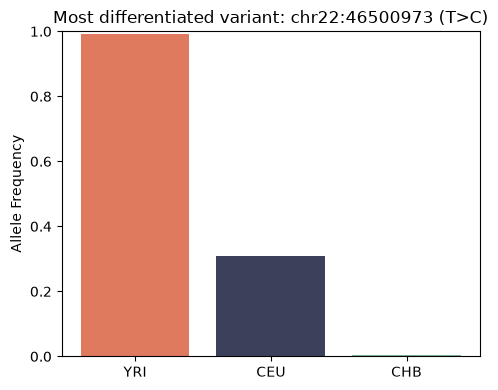

In [5]:
import matplotlib.pyplot as plt

top1 = top_variants.iloc[0]

pops = ["YRI", "CEU", "CHB"]
freqs = [top1["af_YRI"], top1["af_CEU"], top1["af_CHB"]]

plt.figure(figsize=(5, 4))
plt.bar(pops, freqs, color=["#e07a5f", "#3d405b", "#81b29a"])
plt.ylim(0, 1)
plt.ylabel("Allele Frequency")
plt.title(f"Most differentiated variant: chr{top1['chrom']}:{top1['pos']} ({top1['ref']}>{top1['alt']})")
plt.tight_layout()
plt.savefig("../results/top_variant_bar.png", dpi=150)
plt.show()

What this does: top_variants.iloc[0] grabs the single highest-ranked row (the one with the biggest max_diff). The bar chart shows its frequency in each population side-by-side — this is the clearest possible way to show "this variant is nearly universal in one population and nearly absent in another."

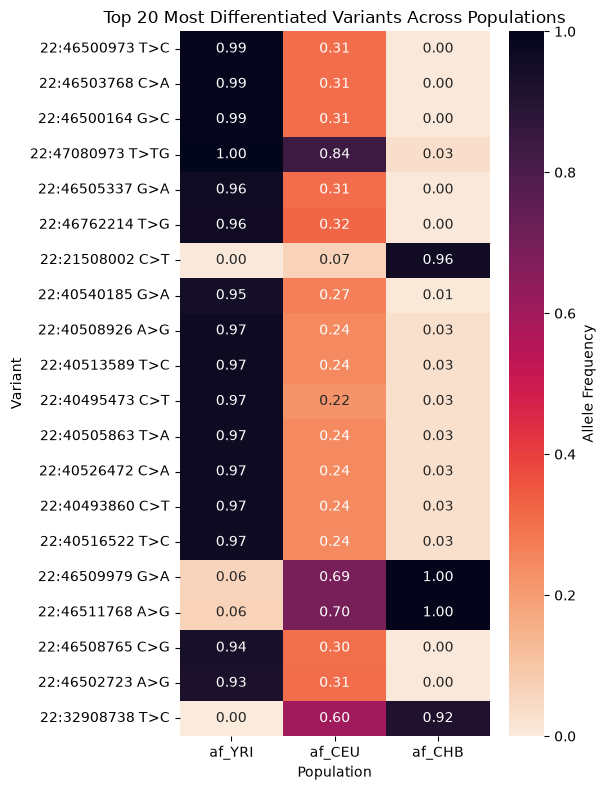

In [6]:
import seaborn as sns

top20 = top_variants.head(20).copy()
top20["label"] = top20["chrom"].astype(str) + ":" + top20["pos"].astype(str) + " " + top20["ref"] + ">" + top20["alt"]

heatmap_data = top20.set_index("label")[["af_YRI", "af_CEU", "af_CHB"]]

plt.figure(figsize=(6, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="rocket_r", cbar_kws={"label": "Allele Frequency"})
plt.title("Top 20 Most Differentiated Variants Across Populations")
plt.xlabel("Population")
plt.ylabel("Variant")
plt.tight_layout()
plt.savefig("../results/top20_heatmap.png", dpi=150)
plt.show()

What this does: builds a label for each variant (its position and base change) to use as a row name, then seaborn.heatmap draws a grid where each row is a variant, each column is a population, and color intensity shows frequency. annot=True prints the actual number inside each cell too. This single chart is extremely effective — you can see at a glance which variants are population-specific and in which direction.

/home/wiam/bioinfo_projects/projet1_population_genetics/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


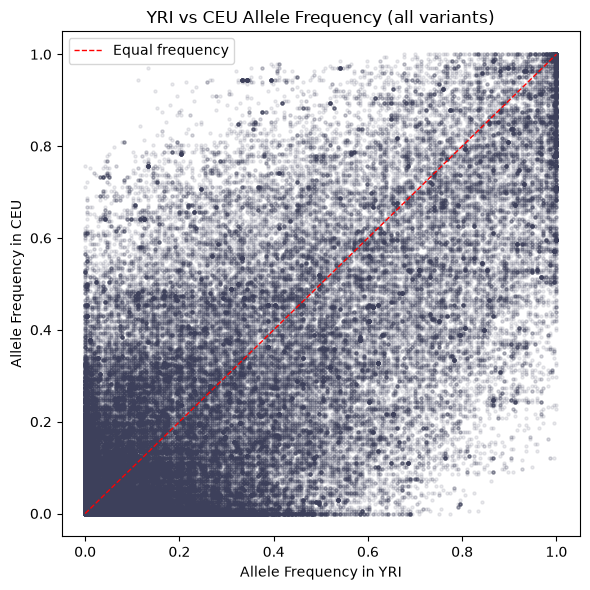

In [7]:
plt.figure(figsize=(6, 6))
plt.scatter(merged["af_YRI"], merged["af_CEU"], alpha=0.1, s=5, color="#3d405b")
plt.plot([0, 1], [0, 1], color="red", linestyle="--", linewidth=1, label="Equal frequency")
plt.xlabel("Allele Frequency in YRI")
plt.ylabel("Allele Frequency in CEU")
plt.title("YRI vs CEU Allele Frequency (all variants)")
plt.legend()
plt.tight_layout()
plt.savefig("../results/yri_vs_ceu_scatter.png", dpi=150)
plt.show()

What this does: plots every single variant as a point, with its YRI frequency on the x-axis and CEU frequency on the y-axis. The dashed red line marks "equal frequency in both populations" — points sitting exactly on that line are identical between populations (most points will cluster near 0,0 since most variants are rare everywhere). Points far from the line, especially in the corners (near 0 in one population, near 1 in the other), are your differentiated variants — this gives a "big picture" view showing that most variation is shared, and only a subset really differs, which is an important and true population genetics insight in its own right.

## Selecting a non-redundant shortlist for VEP

Many top variants cluster at nearby positions with near-identical frequency
patterns (likely inherited together as a block). We thin these out so our
VEP shortlist represents distinct genomic regions, not repeated signals.

In [8]:
# Sort by how differentiated each variant is
candidates = top_variants.sort_values("max_diff", ascending=False).reset_index(drop=True)

shortlist = []
min_distance = 50000  # bases - variants closer than this are considered "the same signal"

for _, row in candidates.iterrows():
    # Check this variant isn't too close to one we already picked
    too_close = False
    for picked in shortlist:
        if abs(row["pos"] - picked["pos"]) < min_distance:
            too_close = True
            break
    if not too_close:
        shortlist.append(row)
    if len(shortlist) == 15:  # stop once we have 15 distinct candidates
        break

shortlist_df = pd.DataFrame(shortlist)
shortlist_df[["chrom", "pos", "ref", "alt", "af_YRI", "af_CEU", "af_CHB", "max_diff"]]

,chrom,pos,ref,alt,af_YRI,af_CEU,af_CHB,max_diff
0,22,46500973,T,C,0.990741,0.308081,0.004854,0.985887
3,22,47080973,T,TG,1.000000,0.843434,0.033981,0.966019
5,22,46762214,T,G,0.958333,0.323232,0.004854,0.953479
6,22,21508002,C,T,0.004630,0.065657,0.956311,0.951681
7,22,40540185,G,A,0.949074,0.267677,0.009709,0.939365
19,22,32908738,T,C,0.000000,0.601010,0.917476,0.917476
20,22,40597667,G,A,0.921296,0.272727,0.009709,0.911587
33,22,46828354,C,G,0.935185,0.267677,0.033981,0.901204
34,22,46652959,A,G,0.958333,0.272727,0.058252,0.900081
36,22,26603876,ATT,A,0.958333,0.545455,0.063107,0.895226


What this does: walks down the ranked list from most to least differentiated, and only keeps a variant if it's more than 50,000 bases away from every variant already picked. This is a simple but effective way to enforce "spread out across the chromosome, not clumped together" — giving us 15 genuinely distinct candidate regions instead of a handful of regions repeated multiple times.

In [9]:
# Reformat for VEP web tool's expected input format:
# chrom  start  end  ref/alt  strand
vep_formatted = shortlist_df[["chrom", "pos", "ref", "alt"]].copy()
vep_formatted["end"] = vep_formatted["pos"] + vep_formatted["ref"].str.len() - 1
vep_formatted["allele"] = vep_formatted["ref"] + "/" + vep_formatted["alt"]
vep_formatted["strand"] = "+"

vep_final = vep_formatted[["chrom", "pos", "end", "allele", "strand"]]
vep_final.to_csv("../data/processed/vep_input_formatted.txt", sep=" ", header=False, index=False)

vep_final

,chrom,pos,end,allele,strand
0,22,46500973,46500973,T/C,+
3,22,47080973,47080973,T/TG,+
5,22,46762214,46762214,T/G,+
6,22,21508002,21508002,C/T,+
7,22,40540185,40540185,G/A,+
19,22,32908738,32908738,T/C,+
20,22,40597667,40597667,G/A,+
33,22,46828354,46828354,C/G,+
34,22,46652959,46652959,A/G,+
36,22,26603876,26603878,ATT/A,+


Before uploading, VEP's web tool expects a very specific format per line (different from the simple 4-column file we saved). The standard format is:

chrom  start  end  allele  strand

Where allele is written as ref/alt. So we need to reformat slightly. Let's fix this in the notebook rather than by hand.

What this does:

end = pos + len(ref) - 1 → for a single-letter variant, start and end are the same position; for multi-letter ones (like our ATT>A deletion), this correctly spans the full reference sequence
allele = ref + "/" + alt → VEP wants the change written as T/C (ref/alt) in one field, not two separate columns
Saves as a space-separated file — VEP's preferred plain format

In [10]:
vep = pd.read_csv("../data/processed/vep_results.tsv", sep="\t", comment="#")

# Extract position from the Location column (format "22:21508002")
vep["pos"] = vep["Location"].str.split(":").str[1].str.split("-").str[0].astype(int)

# Keep one row per variant: prioritize the canonical transcript, else just take the first
vep_simplified = vep.sort_values("CANONICAL", ascending=False).drop_duplicates(subset="pos", keep="first")

vep_simplified = vep_simplified[["pos", "Consequence", "IMPACT", "SYMBOL", "BIOTYPE"]]
vep_simplified

,pos,Consequence,IMPACT,SYMBOL,BIOTYPE
1,26603876,intron_variant,MODIFIER,SEZ6L,protein_coding
7,32908738,3_prime_UTR_variant,MODIFIER,SYN3,protein_coding
11,36556964,5_prime_UTR_variant,MODIFIER,APOL3,protein_coding
32,37342378,downstream_gene_variant,MODIFIER,CSF2RBP1,unprocessed_pseudogene
42,40597667,intron_variant,MODIFIER,TNRC6B,protein_coding
44,42348602,intron_variant&non_coding_transcript_variant,MODIFIER,LINC00634,processed_transcript
47,46500973,intron_variant,MODIFIER,FLJ27365,protein_coding
50,46652959,synonymous_variant,LOW,PKDREJ,protein_coding
51,46762214,intron_variant,MODIFIER,CELSR1,protein_coding
53,46828354,intron_variant,MODIFIER,CELSR1,protein_coding


What this does: VEP gave multiple rows per variant (one per transcript) — we simplify to one row per variant by preferring the CANONICAL transcript (Ensembl's "main representative" transcript for that gene) when available. We keep just the most informative columns: position, consequence type, impact, gene symbol, biotype.


In [11]:
final_results = shortlist_df.merge(vep_simplified, on="pos", how="left")
final_results[["chrom", "pos", "ref", "alt", "af_YRI", "af_CEU", "af_CHB", "max_diff", "SYMBOL", "Consequence", "IMPACT"]]

,chrom,pos,ref,alt,af_YRI,af_CEU,af_CHB,max_diff,SYMBOL,Consequence,IMPACT
0,22,46500973,T,C,0.990741,0.308081,0.004854,0.985887,FLJ27365,intron_variant,MODIFIER
1,22,47080973,T,TG,1.000000,0.843434,0.033981,0.966019,CERK,3_prime_UTR_variant,MODIFIER
2,22,46762214,T,G,0.958333,0.323232,0.004854,0.953479,CELSR1,intron_variant,MODIFIER
3,22,21508002,C,T,0.004630,0.065657,0.956311,0.951681,NaN,intergenic_variant,MODIFIER
4,22,40540185,G,A,0.949074,0.267677,0.009709,0.939365,TNRC6B,intron_variant,MODIFIER
5,22,32908738,T,C,0.000000,0.601010,0.917476,0.917476,SYN3,3_prime_UTR_variant,MODIFIER
6,22,40597667,G,A,0.921296,0.272727,0.009709,0.911587,TNRC6B,intron_variant,MODIFIER
7,22,46828354,C,G,0.935185,0.267677,0.033981,0.901204,CELSR1,intron_variant,MODIFIER
8,22,46652959,A,G,0.958333,0.272727,0.058252,0.900081,PKDREJ,synonymous_variant,LOW
9,22,26603876,ATT,A,0.958333,0.545455,0.063107,0.895226,SEZ6L,intron_variant,MODIFIER


In [12]:
final_results.to_csv("../results/final_variant_annotations.csv", index=False)
print("Saved final results table")

Saved final results table


## Interpretation

Out of 15 highly population-differentiated variants on chromosome 22:

- **None** change a protein's amino acid sequence (no missense or stop-gained variants) — 
  consistent with the expectation that protein-altering mutations are generally kept rare 
  by natural selection, even when regionally differentiated.
- **1 synonymous coding variant** (PKDREJ) — alters the DNA within a protein-coding exon, 
  but due to genetic code redundancy, the resulting protein is unchanged.
- **Most variants fall in introns or UTRs** of real, protein-coding genes (TNRC6B, CELSR1, 
  SEZ6L, SYN3, APOL3, CERK, FLJ27365) — plausible candidates for affecting gene regulation 
  or expression levels, without directly altering protein structure.
- **2 variants are intergenic** — statistically strong population differences with no 
  nearby gene, a reminder that not all differentiated regions have an obvious functional story.
- Several variants cluster into the same gene (TNRC6B: 3 variants; CELSR1: 2 variants) — 
  consistent with genetic linkage, where nearby variants are inherited together as a block 
  rather than independently.

One gene, **APOL3**, stands out as biologically noteworthy: it belongs to the Apolipoprotein L 
family, which includes APOL1 — a well-documented example of a gene under different evolutionary 
pressure across populations, linked to trypanosome (sleeping sickness) resistance in African 
ancestry populations. While this specific variant's functional significance isn't established 
here, it is a plausible candidate worth flagging for further investigation.